In [1]:
# ============================================================
# Dissertation Chapter 3
# Co-funding Network Analysis (LIS)
#
# Dataset:
# LIS_data_cleaned_with_OND.csv
#
# Research Questions:
# RQ1. Central funders
# RQ2. Funder communities
# RQ3. Temporal evolution
# RQ4. Quartile differences
# ============================================================

0. Install

In [11]:
# ============================================================
# Package Installation
# ============================================================

import sys

!{sys.executable} -m pip install networkx python-louvain

  Using cached python-louvain-0.16.tar.gz (204 kB)
Using legacy 'setup.py install' for python-louvain, since package 'wheel' is not installed.
    Running setup.py install for python-louvain: started
    Running setup.py install for python-louvain: finished with status 'done'


You should consider upgrading via the 'c:\users\jkimi\appdata\local\programs\python\python37\python.exe -m pip install --upgrade pip' command.


1. Create co-funding edge list

In [2]:
# ============================================================
# Step 1:
# Create co-funding edge list from Funding_Details_OND
# ============================================================

import pandas as pd
import ast
from itertools import combinations
from collections import Counter

# ------------------------------------------------------------
# Load LIS dataset
# ------------------------------------------------------------

df = pd.read_csv("LIS_data_cleaned_with_OND.csv")

# ------------------------------------------------------------
# Function:
# Convert Funding_Details_OND into a list of funders
# ------------------------------------------------------------

def parse_funders(x):

    if pd.isna(x):
        return []

    x = str(x).strip()

    if x in ["", "[]", "nan", "None", "NaN"]:
        return []

    try:
        funders = ast.literal_eval(x)

        if isinstance(funders, list):
            return [
                str(f).strip()
                for f in funders
                if str(f).strip()
            ]

    except:
        pass

    return [
        f.strip()
        for f in x.split(";")
        if f.strip()
    ]

# ------------------------------------------------------------
# Create funder list and funder count
# ------------------------------------------------------------

df["Funder_List"] = df["Funding_Details_OND"].apply(parse_funders)

df["Funder_Count"] = df["Funder_List"].apply(len)

# ------------------------------------------------------------
# Keep only co-funded papers
#
# Co-funded paper:
# A paper with two or more funders
# ------------------------------------------------------------

cofunded_df = df[
    df["Funder_Count"] >= 2
].copy()

print("Total papers:", len(df))
print("Co-funded papers:", len(cofunded_df))

# ------------------------------------------------------------
# Create co-funding pairs
#
# Example:
# ['NSF', 'NIH', 'DOE']
#
# becomes:
# ('DOE', 'NIH')
# ('DOE', 'NSF')
# ('NIH', 'NSF')
# ------------------------------------------------------------

edge_records = []

for _, row in cofunded_df.iterrows():

    paper_id = row["Paper_id"]
    year = row["Year"]
    source_title = row["Source title"]
    funders = row["Funder_List"]

    # Remove duplicated funders within the same paper
    funders = sorted(set(funders))

    # Create all unordered funder pairs
    for funder_a, funder_b in combinations(funders, 2):

        edge_records.append({
            "Paper_id": paper_id,
            "Year": year,
            "Source title": source_title,
            "Funder_A": funder_a,
            "Funder_B": funder_b
        })

# ------------------------------------------------------------
# Paper-level edge list
#
# Each row represents one co-funding relationship
# observed in one paper.
# ------------------------------------------------------------

paper_edge_list = pd.DataFrame(edge_records)

print("Paper-level co-funding edges:", len(paper_edge_list))

paper_edge_list.head()

Total papers: 80794
Co-funded papers: 18674
Paper-level co-funding edges: 109075


,Paper_id,Year,Source title,Funder_A,Funder_B
0,10000009,2024,Accountability in Research,"Chief Scientist Office, Scottish Government He...",Ministry of Health
1,10000022,2024,Accountability in Research,National Policy for Science,National Science Board
2,10000022,2024,Accountability in Research,National Policy for Science,National Science Foundation
3,10000022,2024,Accountability in Research,National Science Board,National Science Foundation
4,10000026,2024,Accountability in Research,European Commission,Horizon 2020 Framework Programme


2. Create weighted co-funding edge list

In [3]:
# ============================================================
# Step 2:
# Create weighted co-funding edge list
# Compatible with older pandas versions
# ============================================================

weighted_edge_list = (
    paper_edge_list
    .groupby(["Funder_A", "Funder_B"])
    .agg({
        "Paper_id": "count",
        "Year": ["min", "max"]
    })
    .reset_index()
)

# Rename columns
weighted_edge_list.columns = [
    "Funder_A",
    "Funder_B",
    "Weight",
    "First_Year",
    "Last_Year"
]

# Sort by edge weight
weighted_edge_list = weighted_edge_list.sort_values(
    "Weight",
    ascending=False
)

weighted_edge_list.head(20)

,Funder_A,Funder_B,Weight,First_Year,Last_Year
35718,Fundamental Research Funds for the Central Uni...,National Natural Science Foundation of China,576,2014,2024
58822,National Key Research and Development Program ...,National Natural Science Foundation of China,548,2014,2024
25836,Directorate for Computer and Information Scien...,National Science Foundation,376,2014,2024
58173,National Institutes of Health,National Science Foundation,346,2014,2024
16964,China Postdoctoral Science Foundation,National Natural Science Foundation of China,340,2014,2024
53252,Ministry of Education of the People's Republic...,National Natural Science Foundation of China,293,2014,2024
31781,European Research Council,Horizon 2020 Framework Programme,268,2016,2024
57749,National Institute of General Medical Sciences,National Institutes of Health,266,2014,2024
59268,National Natural Science Foundation of China,National Office for Philosophy and Social Scie...,214,2014,2024
20272,Conselho Nacional de Desenvolvimento Científic...,Coordenação de Aperfeiçoamento de Pessoal de N...,209,2014,2024


In [4]:
# ============================================================
# Summary statistics
# ============================================================

print("Number of co-funded papers:", len(cofunded_df))

print("Number of paper-level co-funding edges:", len(paper_edge_list))

print("Number of unique funder pairs:", len(weighted_edge_list))

print("Number of unique funders in co-funding network:")

unique_funders = set(weighted_edge_list["Funder_A"]).union(
    set(weighted_edge_list["Funder_B"])
)

print(len(unique_funders))

Number of co-funded papers: 18674
Number of paper-level co-funding edges: 109075
Number of unique funder pairs: 70402
Number of unique funders in co-funding network:
9699


In [5]:
# ------------------------------------------------------------
# Save edge lists
# ------------------------------------------------------------

paper_edge_list.to_csv(
    "paper_level_cofunding_edge_list_LIS.csv",
    index=False
)

weighted_edge_list.to_csv(
    "weighted_cofunding_edge_list_LIS.csv",
    index=False
)

3. Build Whole-period Network

In [6]:
# ============================================================
# Step 3
# Build Whole-period Co-funding Network
# Period: 2014–2024
# ============================================================

import networkx as nx

print(nx.__version__)

# ------------------------------------------------------------
# Create an undirected weighted graph
# ------------------------------------------------------------

G = nx.Graph()

# ------------------------------------------------------------
# Add weighted edges
#
# Node:
#   Funder
#
# Edge:
#   Co-funding relationship between two funders
#
# Weight:
#   Number of papers co-funded by the two funders
# ------------------------------------------------------------

for _, row in weighted_edge_list.iterrows():

    G.add_edge(
        row["Funder_A"],
        row["Funder_B"],
        weight=row["Weight"],
        first_year=row["First_Year"],
        last_year=row["Last_Year"]
    )

# ------------------------------------------------------------
# Basic network summary
# ------------------------------------------------------------

num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()
density = nx.density(G)

print("Whole-period LIS Co-funding Network")
print("-----------------------------------")
print(f"Number of nodes: {num_nodes}")
print(f"Number of edges: {num_edges}")
print(f"Network density: {density:.6f}")

2.6.3
Whole-period LIS Co-funding Network
-----------------------------------
Number of nodes: 9699
Number of edges: 70402
Network density: 0.001497


In [7]:
# ============================================================
# Connected Components
# ============================================================

components = list(nx.connected_components(G))

num_components = len(components)

largest_component = max(
    components,
    key=len
)

largest_component_size = len(largest_component)

print("Connected Components")
print("--------------------")
print(f"Number of connected components: {num_components}")
print(f"Largest component size: {largest_component_size}")
print(
    f"Largest component share: "
    f"{largest_component_size / num_nodes * 100:.2f}%"
)

Connected Components
--------------------
Number of connected components: 122
Largest component size: 9432
Largest component share: 97.25%


In [8]:
# ============================================================
# Whole-period Network-level Metrics
# ============================================================

# Average degree
avg_degree = sum(dict(G.degree()).values()) / num_nodes

# Average weighted degree
avg_weighted_degree = sum(
    dict(G.degree(weight="weight")).values()
) / num_nodes

# Clustering coefficient
avg_clustering = nx.average_clustering(G)

# Weighted clustering coefficient
avg_weighted_clustering = nx.average_clustering(
    G,
    weight="weight"
)

print("Network-level Metrics")
print("---------------------")
print(f"Average degree: {avg_degree:.3f}")
print(f"Average weighted degree: {avg_weighted_degree:.3f}")
print(f"Average clustering coefficient: {avg_clustering:.3f}")
print(f"Average weighted clustering coefficient: {avg_weighted_clustering:.3f}")

Network-level Metrics
---------------------
Average degree: 14.517
Average weighted degree: 22.492
Average clustering coefficient: 0.657
Average weighted clustering coefficient: 0.002


In [9]:
# ============================================================
# Average Path Length
# Calculated only for the largest connected component
# ============================================================

G_lcc = G.subgraph(largest_component).copy()

if G_lcc.number_of_nodes() > 1:
    avg_path_length = nx.average_shortest_path_length(G_lcc)
    diameter = nx.diameter(G_lcc)

    print("Largest Connected Component Metrics")
    print("-----------------------------------")
    print(f"Average path length: {avg_path_length:.3f}")
    print(f"Diameter: {diameter}")
else:
    print("Largest connected component has fewer than 2 nodes.")

Largest Connected Component Metrics
-----------------------------------
Average path length: 3.054
Diameter: 8


In [10]:
# ============================================================
# Table 3.X
# Whole-period Co-funding Network Summary
# ============================================================

whole_network_summary = pd.DataFrame({
    "Network": ["LIS co-funding network"],
    "Period": ["2014-2024"],
    "Nodes": [num_nodes],
    "Edges": [num_edges],
    "Density": [density],
    "Connected Components": [num_components],
    "Largest Component Size": [largest_component_size],
    "Largest Component Share (%)": [
        largest_component_size / num_nodes * 100
    ],
    "Average Degree": [avg_degree],
    "Average Weighted Degree": [avg_weighted_degree],
    "Average Clustering": [avg_clustering],
    "Average Weighted Clustering": [avg_weighted_clustering]
})

whole_network_summary = whole_network_summary.round(4)

whole_network_summary

,Network,Period,Nodes,Edges,Density,Connected Components,Largest Component Size,Largest Component Share (%),Average Degree,Average Weighted Degree,Average Clustering,Average Weighted Clustering
0,LIS co-funding network,2014-2024,9699,70402,0.0015,122,9432,97.2471,14.5174,22.492,0.6568,0.0019


In [17]:
whole_network_summary.to_csv(
    "Table_Whole_Period_Cofunding_Network_Summary_LIS.csv",
    index=False
)

4. Centrality Analysis

In [19]:
# ============================================================
# Step 4
# Centrality Analysis
# Whole-period LIS Co-funding Network, 2014–2024
# ============================================================

import pandas as pd
import networkx as nx

# ------------------------------------------------------------
# Degree
# Number of unique co-funding partners
# ------------------------------------------------------------

degree_dict = dict(G.degree())

# ------------------------------------------------------------
# Weighted degree
# Sum of edge weights connected to each funder
# ------------------------------------------------------------

weighted_degree_dict = dict(
    G.degree(weight="weight")
)

# ------------------------------------------------------------
# Degree centrality
# Normalized degree centrality
# ------------------------------------------------------------

degree_centrality_dict = nx.degree_centrality(G)

# ------------------------------------------------------------
# Betweenness centrality
#
# For weighted networks, distance should be inverse of weight:
# stronger co-funding relationship = shorter distance
# ------------------------------------------------------------

for u, v, data in G.edges(data=True):
    data["distance"] = 1 / data["weight"]

# Use approximate betweenness centrality
betweenness_dict = nx.betweenness_centrality(
    G,
    k=500,
    weight="distance",
    normalized=True,
    seed=42
)

# ------------------------------------------------------------
# Create centrality table
# ------------------------------------------------------------

centrality_df = pd.DataFrame({
    "Funder": list(G.nodes()),
    "Degree": [degree_dict[n] for n in G.nodes()],
    "Weighted Degree": [weighted_degree_dict[n] for n in G.nodes()],
    "Degree Centrality": [degree_centrality_dict[n] for n in G.nodes()],
    "Betweenness Centrality": [betweenness_dict[n] for n in G.nodes()]
})

centrality_df = centrality_df.sort_values(
    "Weighted Degree",
    ascending=False
)

centrality_df.head(20)

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality
1,National Natural Science Foundation of China,2454,9705,0.253042,0.533333
4,National Science Foundation,1556,5791,0.160445,0.628595
5,National Institutes of Health,1263,4180,0.130233,0.208275
9,Horizon 2020 Framework Programme,960,2895,0.098989,0.231739
16,European Commission,976,2695,0.100639,0.169850
0,Fundamental Research Funds for the Central Uni...,641,2106,0.066096,0.011568
8,European Research Council,700,2084,0.072180,0.080051
2,National Key Research and Development Program ...,636,2024,0.065581,0.011159
27,European Regional Development Fund,764,1994,0.078779,0.098537
17,Seventh Framework Programme,585,1666,0.060322,0.016093


In [20]:
# ============================================================
# Table 3.X
# Top 20 Funders by Degree
# ============================================================

top20_degree = (
    centrality_df
    .sort_values("Degree", ascending=False)
    .head(20)
    .copy()
)

top20_degree

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality
1,National Natural Science Foundation of China,2454,9705,0.253042,0.533333
4,National Science Foundation,1556,5791,0.160445,0.628595
5,National Institutes of Health,1263,4180,0.130233,0.208275
16,European Commission,976,2695,0.100639,0.169850
9,Horizon 2020 Framework Programme,960,2895,0.098989,0.231739
27,European Regional Development Fund,764,1994,0.078779,0.098537
8,European Research Council,700,2084,0.072180,0.080051
0,Fundamental Research Funds for the Central Uni...,641,2106,0.066096,0.011568
2,National Key Research and Development Program ...,636,2024,0.065581,0.011159
17,Seventh Framework Programme,585,1666,0.060322,0.016093


In [21]:
# ============================================================
# Table 3.X
# Top 20 Funders by Weighted Degree
# ============================================================

top20_weighted_degree = (
    centrality_df
    .sort_values("Weighted Degree", ascending=False)
    .head(20)
    .copy()
)

top20_weighted_degree

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality
1,National Natural Science Foundation of China,2454,9705,0.253042,0.533333
4,National Science Foundation,1556,5791,0.160445,0.628595
5,National Institutes of Health,1263,4180,0.130233,0.208275
9,Horizon 2020 Framework Programme,960,2895,0.098989,0.231739
16,European Commission,976,2695,0.100639,0.169850
0,Fundamental Research Funds for the Central Uni...,641,2106,0.066096,0.011568
8,European Research Council,700,2084,0.072180,0.080051
2,National Key Research and Development Program ...,636,2024,0.065581,0.011159
27,European Regional Development Fund,764,1994,0.078779,0.098537
17,Seventh Framework Programme,585,1666,0.060322,0.016093


In [22]:
# ============================================================
# Table 3.X
# Top 20 Funders by Betweenness Centrality
# ============================================================

top20_betweenness = (
    centrality_df
    .sort_values("Betweenness Centrality", ascending=False)
    .head(20)
    .copy()
)

top20_betweenness

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality
4,National Science Foundation,1556,5791,0.160445,0.628595
1,National Natural Science Foundation of China,2454,9705,0.253042,0.533333
9,Horizon 2020 Framework Programme,960,2895,0.098989,0.231739
5,National Institutes of Health,1263,4180,0.130233,0.208275
16,European Commission,976,2695,0.100639,0.169850
27,European Regional Development Fund,764,1994,0.078779,0.098537
8,European Research Council,700,2084,0.072180,0.080051
12,Conselho Nacional de Desenvolvimento Científic...,414,1167,0.042689,0.058506
15,National Research Foundation of Korea,264,1085,0.027222,0.054859
32,Deutsche Forschungsgemeinschaft,573,1354,0.059084,0.047895


In [23]:
# ============================================================
# Save centrality results
# ============================================================

centrality_df.to_csv(
    "centrality_results_LIS_whole_period.csv",
    index=False
)

top20_degree.to_csv(
    "top20_funders_by_degree_LIS.csv",
    index=False
)

top20_weighted_degree.to_csv(
    "top20_funders_by_weighted_degree_LIS.csv",
    index=False
)

top20_betweenness.to_csv(
    "top20_funders_by_betweenness_LIS.csv",
    index=False
)

5. Louvain community detection

In [24]:
# ============================================================
# Step 5
# Louvain Community Detection
# ============================================================

import community as community_louvain

partition = community_louvain.best_partition(
    G,
    weight="weight",
    random_state=42
)

# Add community information to centrality table
centrality_df["Community"] = centrality_df["Funder"].map(partition)

centrality_df.head()

,Funder,Degree,Weighted Degree,Degree Centrality,Betweenness Centrality,Community
1,National Natural Science Foundation of China,2454,9705,0.253042,0.533333,0
4,National Science Foundation,1556,5791,0.160445,0.628595,1
5,National Institutes of Health,1263,4180,0.130233,0.208275,1
9,Horizon 2020 Framework Programme,960,2895,0.098989,0.231739,2
16,European Commission,976,2695,0.100639,0.169850,2


In [25]:
# ============================================================
# Community Summary
# ============================================================

community_summary = (
    centrality_df
    .groupby("Community")
    .agg(
        Number_of_Funders=("Funder", "count"),
        Avg_Degree=("Degree", "mean"),
        Avg_Weighted_Degree=("Weighted Degree", "mean"),
        Avg_Betweenness=("Betweenness Centrality", "mean")
    )
    .reset_index()
    .sort_values("Number_of_Funders", ascending=False)
)

community_summary = community_summary.round(4)

community_summary

,Community,Number_of_Funders,Avg_Degree,Avg_Weighted_Degree,Avg_Betweenness
0,0,2364,11.5431,21.1641,0.0003
2,2,2215,16.2826,25.5061,0.0004
1,1,1628,19.8667,32.1978,0.0007
4,4,870,12.5138,18.8977,0.0003
7,7,644,15.2298,17.3059,0.0001
...,...,...,...,...,...
66,66,2,1.0000,1.0000,0.0000
65,65,2,1.0000,1.0000,0.0000
64,64,2,1.0000,1.0000,0.0000
60,60,2,1.0000,1.0000,0.0000


In [26]:
# ============================================================
# Community Summary Table
# ============================================================

# Top funders within each community by weighted degree
def get_top_funders(group, n=5):
    return "; ".join(
        group
        .sort_values("Weighted Degree", ascending=False)
        ["Funder"]
        .head(n)
    )

community_summary_table = (
    centrality_df
    .groupby("Community")
    .apply(
        lambda g: pd.Series({
            "Number of Funders": len(g),
            "Top Funders": get_top_funders(g, n=5),
            "Average Degree": g["Degree"].mean(),
            "Average Weighted Degree": g["Weighted Degree"].mean(),
            "Average Betweenness": g["Betweenness Centrality"].mean(),
            "Max Weighted Degree": g["Weighted Degree"].max(),
            "Most Central Funder": (
                g.sort_values("Weighted Degree", ascending=False)
                 ["Funder"]
                 .iloc[0]
            )
        })
    )
    .reset_index()
)

community_summary_table = community_summary_table.sort_values(
    "Number of Funders",
    ascending=False
)

community_summary_table[
    [
        "Average Degree",
        "Average Weighted Degree",
        "Average Betweenness"
    ]
] = community_summary_table[
    [
        "Average Degree",
        "Average Weighted Degree",
        "Average Betweenness"
    ]
].round(4)

community_summary_table

,Community,Number of Funders,Top Funders,Average Degree,Average Weighted Degree,Average Betweenness,Max Weighted Degree,Most Central Funder
0,0,2364,National Natural Science Foundation of China; ...,11.5431,21.1641,0.0003,9705,National Natural Science Foundation of China
2,2,2215,Horizon 2020 Framework Programme; European Com...,16.2826,25.5061,0.0004,2895,Horizon 2020 Framework Programme
1,1,1628,National Science Foundation; National Institut...,19.8667,32.1978,0.0007,5791,National Science Foundation
4,4,870,National Science and Technology Council; Natio...,12.5138,18.8977,0.0003,1163,National Science and Technology Council
7,7,644,Institute of Museum and Library Services; Univ...,15.2298,17.3059,0.0001,418,Institute of Museum and Library Services
...,...,...,...,...,...,...,...,...
66,66,2,Research Institute for Artificial Intelligence...,1.0000,1.0000,0.0000,1,Research Institute for Artificial Intelligence...
65,65,2,"Research Network Communication, Media and Poli...",1.0000,1.0000,0.0000,1,"Research Network Communication, Media and Poli..."
64,64,2,Rowan University; Rochelle Mead-Wroniuk,1.0000,1.0000,0.0000,1,Rowan University
60,60,2,Postgraduate Research Budget of Damascus Unive...,1.0000,1.0000,0.0000,1,Postgraduate Research Budget of Damascus Unive...


In [27]:
community_summary_table.to_csv(
    "Table_Community_Summary_LIS.csv",
    index=False
)

In [28]:
table_major_communities = (
    community_summary_table
    .head(10)
    .copy()
)

table_major_communities

,Community,Number of Funders,Top Funders,Average Degree,Average Weighted Degree,Average Betweenness,Max Weighted Degree,Most Central Funder
0,0,2364,National Natural Science Foundation of China; ...,11.5431,21.1641,0.0003,9705,National Natural Science Foundation of China
2,2,2215,Horizon 2020 Framework Programme; European Com...,16.2826,25.5061,0.0004,2895,Horizon 2020 Framework Programme
1,1,1628,National Science Foundation; National Institut...,19.8667,32.1978,0.0007,5791,National Science Foundation
4,4,870,National Science and Technology Council; Natio...,12.5138,18.8977,0.0003,1163,National Science and Technology Council
7,7,644,Institute of Museum and Library Services; Univ...,15.2298,17.3059,0.0001,418,Institute of Museum and Library Services
6,6,414,Natural Sciences and Engineering Research Coun...,13.9275,18.1014,0.0001,824,Natural Sciences and Engineering Research Coun...
5,5,298,Japan Society for the Promotion of Science; Mi...,10.5671,15.0403,0.0001,1089,Japan Society for the Promotion of Science
3,3,297,Conselho Nacional de Desenvolvimento Científic...,11.6330,19.8990,0.0002,1167,Conselho Nacional de Desenvolvimento Científic...
8,8,239,Max-Planck-Gesellschaft; Andrew W. Mellon Foun...,26.8326,29.5272,0.0001,246,Max-Planck-Gesellschaft
11,11,135,"Deanship of Scientific Research, King Saud Uni...",9.4667,10.1556,0.0000,117,"Deanship of Scientific Research, King Saud Uni..."


In [29]:
table_major_communities.to_csv(
    "Table_Major_Communities_LIS.csv",
    index=False
)

6. Visualization

Visualization network
---------------------
Nodes: 736
Edges: 1980


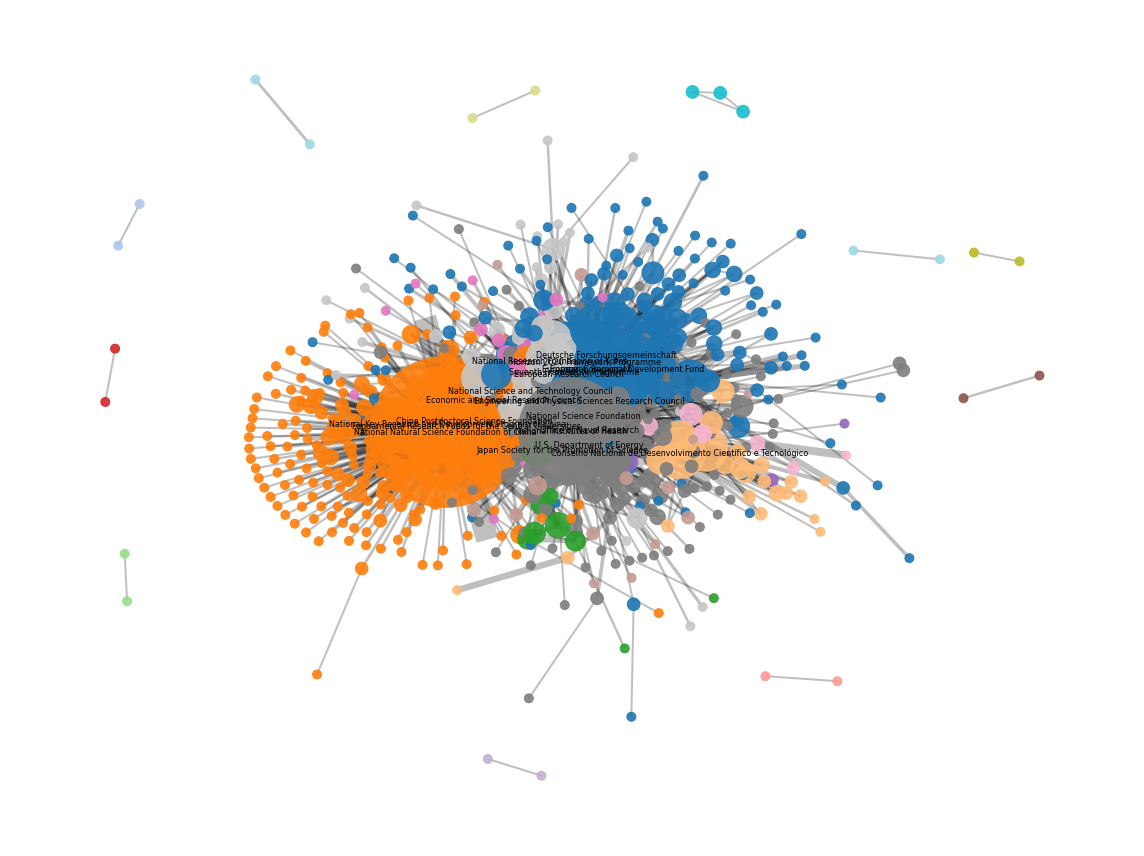

In [33]:
# ============================================================
# Figure 3.8
# Whole-period LIS Co-funding Network, 2014–2024
#
# Node size = degree
# Edge width = co-funding frequency
# Node color = Louvain community
# ============================================================

import matplotlib.pyplot as plt
import networkx as nx

# ------------------------------------------------------------
# Filter graph for visualization
#
# Keep edges with weight >= 2
# This improves readability.
# ------------------------------------------------------------

min_edge_weight = 5

edges_to_keep = [
    (u, v)
    for u, v, d in G.edges(data=True)
    if d["weight"] >= min_edge_weight
]

G_vis = G.edge_subgraph(edges_to_keep).copy()

print("Visualization network")
print("---------------------")
print("Nodes:", G_vis.number_of_nodes())
print("Edges:", G_vis.number_of_edges())

# ------------------------------------------------------------
# Louvain communities for visualization graph
# ------------------------------------------------------------

partition_vis = community_louvain.best_partition(
    G_vis,
    weight="weight",
    random_state=42
)

# ------------------------------------------------------------
# Node size = degree
# ------------------------------------------------------------

degree_vis = dict(G_vis.degree())

node_sizes = [
    degree_vis[n] * 80
    for n in G_vis.nodes()
]

# ------------------------------------------------------------
# Node color = community
# ------------------------------------------------------------

node_colors = [
    partition_vis[n]
    for n in G_vis.nodes()
]

# ------------------------------------------------------------
# Edge width = edge weight
# ------------------------------------------------------------

edge_widths = [
    G_vis[u][v]["weight"] * 0.4
    for u, v in G_vis.edges()
]

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

pos = nx.spring_layout(
    G_vis,
    weight="weight",
    seed=42,
    k=0.25
)

# ------------------------------------------------------------
# Draw network
# ------------------------------------------------------------

plt.figure(figsize=(16, 12))

nx.draw_networkx_edges(
    G_vis,
    pos,
    width=edge_widths,
    alpha=0.25
)

nx.draw_networkx_nodes(
    G_vis,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.tab20,
    alpha=0.9
)

# ------------------------------------------------------------
# Label only top funders by degree
# ------------------------------------------------------------

top_label_nodes = (
    pd.Series(degree_vis)
    .sort_values(ascending=False)
    .head(20)
    .index
)

labels = {
    node: node
    for node in top_label_nodes
}

nx.draw_networkx_labels(
    G_vis,
    pos,
    labels=labels,
    font_size=8
)

# plt.title(
#     "Figure 3.8. Whole-period LIS Co-funding Network, 2014–2024"
# )

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "Figure_3_8_Whole_Period_Cofunding_Network_LIS.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_8_Whole_Period_Cofunding_Network_LIS.pdf",
    bbox_inches="tight"
)

plt.show()

Top funders network
-------------------
Nodes: 100
Edges: 2526


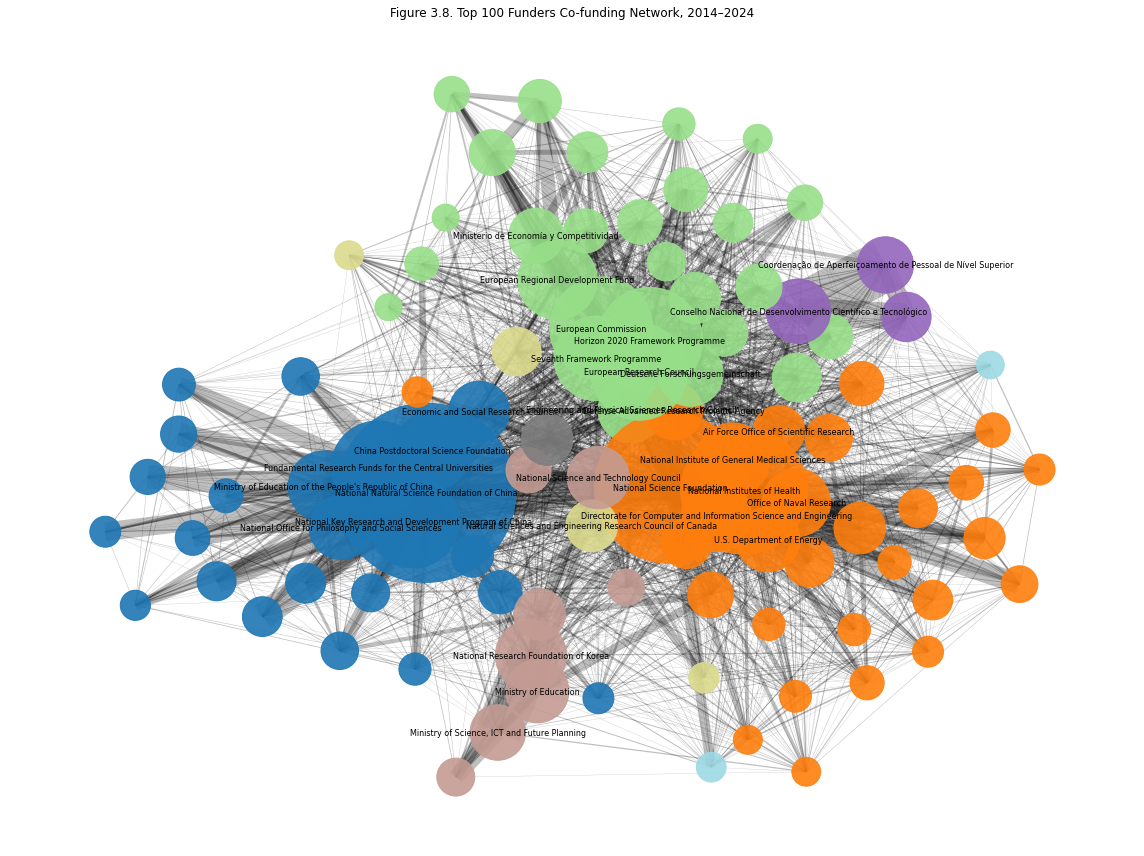

In [34]:
# ============================================================
# Figure 3.8
# Top 100 Funders Co-funding Network
#
# Node size = weighted degree
# Edge width = co-funding frequency
# Node color = Louvain community
# ============================================================

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

# ------------------------------------------------------------
# Select top 100 funders by weighted degree
# ------------------------------------------------------------

top_n = 100

top_funders = (
    centrality_df
    .sort_values("Weighted Degree", ascending=False)
    .head(top_n)
    ["Funder"]
    .tolist()
)

G_top = G.subgraph(top_funders).copy()

print("Top funders network")
print("-------------------")
print("Nodes:", G_top.number_of_nodes())
print("Edges:", G_top.number_of_edges())

# ------------------------------------------------------------
# Node attributes
# ------------------------------------------------------------

weighted_degree_top = dict(
    G_top.degree(weight="weight")
)

degree_top = dict(
    G_top.degree()
)

community_map = dict(
    zip(
        centrality_df["Funder"],
        centrality_df["Community"]
    )
)

node_sizes = [
    weighted_degree_top[n] * 8
    for n in G_top.nodes()
]

node_colors = [
    community_map.get(n, -1)
    for n in G_top.nodes()
]

edge_widths = [
    max(0.3, G_top[u][v]["weight"] * 0.25)
    for u, v in G_top.edges()
]

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

pos = nx.spring_layout(
    G_top,
    weight="weight",
    seed=42,
    k=0.45,
    iterations=100
)

# ------------------------------------------------------------
# Draw network
# ------------------------------------------------------------

plt.figure(figsize=(16, 12))

nx.draw_networkx_edges(
    G_top,
    pos,
    width=edge_widths,
    alpha=0.25
)

nx.draw_networkx_nodes(
    G_top,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.tab20,
    alpha=0.9
)

# Label top 30 funders by weighted degree
top_label_nodes = (
    pd.Series(weighted_degree_top)
    .sort_values(ascending=False)
    .head(30)
    .index
)

labels = {
    node: node
    for node in top_label_nodes
}

nx.draw_networkx_labels(
    G_top,
    pos,
    labels=labels,
    font_size=8
)

plt.title(
    "Figure 3.8. Top 100 Funders Co-funding Network, 2014–2024"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "Figure_3_8_Top100_Funders_Cofunding_Network_LIS.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_8_Top100_Funders_Cofunding_Network_LIS.pdf",
    bbox_inches="tight"
)

plt.show()

Community network
-----------------
Communities: 148
Between-community edges: 109
Major community network
-----------------------
Communities: 15
Edges: 75


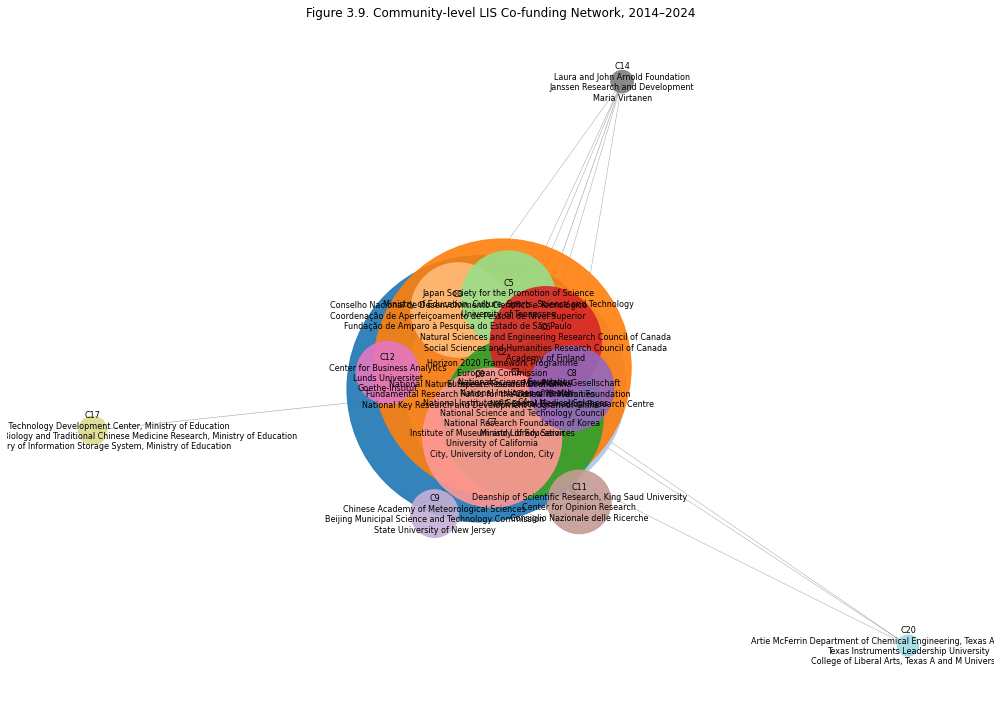

In [35]:
# ============================================================
# Figure 3.9
# Community-level Co-funding Network
#
# Node = Louvain community
# Node size = number of funders in community
# Edge width = total co-funding weight between communities
# ============================================================

import networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict

# ------------------------------------------------------------
# Community assignment
# ------------------------------------------------------------

community_map = dict(
    zip(
        centrality_df["Funder"],
        centrality_df["Community"]
    )
)

# ------------------------------------------------------------
# Create community-level graph
# ------------------------------------------------------------

G_comm = nx.Graph()

# Add community nodes
community_sizes = (
    centrality_df
    .groupby("Community")
    ["Funder"]
    .count()
    .to_dict()
)

for comm, size in community_sizes.items():
    G_comm.add_node(
        comm,
        size=size
    )

# Add community-level edges
for u, v, data in G.edges(data=True):

    comm_u = community_map.get(u)
    comm_v = community_map.get(v)

    if comm_u is None or comm_v is None:
        continue

    # Skip within-community edges for between-community network
    if comm_u == comm_v:
        continue

    weight = data["weight"]

    if G_comm.has_edge(comm_u, comm_v):
        G_comm[comm_u][comm_v]["weight"] += weight
    else:
        G_comm.add_edge(
            comm_u,
            comm_v,
            weight=weight
        )

print("Community network")
print("-----------------")
print("Communities:", G_comm.number_of_nodes())
print("Between-community edges:", G_comm.number_of_edges())

# ------------------------------------------------------------
# Optional:
# Keep only major communities
# ------------------------------------------------------------

min_community_size = 10

major_communities = [
    comm
    for comm, size in community_sizes.items()
    if size >= min_community_size
]

G_comm_vis = G_comm.subgraph(major_communities).copy()

print("Major community network")
print("-----------------------")
print("Communities:", G_comm_vis.number_of_nodes())
print("Edges:", G_comm_vis.number_of_edges())

# ------------------------------------------------------------
# Node size and edge width
# ------------------------------------------------------------

node_sizes = [
    G_comm_vis.nodes[n]["size"] * 30
    for n in G_comm_vis.nodes()
]

edge_widths = [
    max(0.5, G_comm_vis[u][v]["weight"] * 0.02)
    for u, v in G_comm_vis.edges()
]

# ------------------------------------------------------------
# Labels:
# Community number + top funders
# ------------------------------------------------------------

community_top_funders = {}

for comm in G_comm_vis.nodes():

    top_funders = (
        centrality_df[
            centrality_df["Community"] == comm
        ]
        .sort_values("Weighted Degree", ascending=False)
        ["Funder"]
        .head(3)
        .tolist()
    )

    community_top_funders[comm] = (
        f"C{comm}\n" + "\n".join(top_funders)
    )

# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

pos = nx.spring_layout(
    G_comm_vis,
    weight="weight",
    seed=42,
    k=1.2,
    iterations=100
)

# ------------------------------------------------------------
# Draw community network
# ------------------------------------------------------------

plt.figure(figsize=(14, 10))

nx.draw_networkx_edges(
    G_comm_vis,
    pos,
    width=edge_widths,
    alpha=0.35
)

nx.draw_networkx_nodes(
    G_comm_vis,
    pos,
    node_size=node_sizes,
    node_color=list(G_comm_vis.nodes()),
    cmap=plt.cm.tab20,
    alpha=0.9
)

nx.draw_networkx_labels(
    G_comm_vis,
    pos,
    labels=community_top_funders,
    font_size=8
)

plt.title(
    "Figure 3.9. Community-level LIS Co-funding Network, 2014–2024"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "Figure_3_9_Community_Level_Cofunding_Network_LIS.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_9_Community_Level_Cofunding_Network_LIS.pdf",
    bbox_inches="tight"
)

plt.show()

7. Network Statistics Over Time

In [11]:
# ============================================================
# Table 3.6
# Network Statistics Over Time
#
# Unit of analysis:
# Annual co-funding networks
#
# Node:
# Funding organization
#
# Edge:
# Co-funding relationship between two funders
#
# Edge weight:
# Number of co-funded papers in a given year
# ============================================================

import pandas as pd
import networkx as nx

# ------------------------------------------------------------
# Function:
# Build annual co-funding network from paper-level edge list
# ------------------------------------------------------------

def build_annual_network(edge_df, year):

    # Select edges observed in the given year
    year_edges = edge_df[
        edge_df["Year"] == year
    ].copy()

    # Aggregate repeated co-funding pairs within the year
    annual_weighted_edges = (
        year_edges
        .groupby(["Funder_A", "Funder_B"])
        .size()
        .reset_index(name="Weight")
    )

    # Create graph
    G_year = nx.Graph()

    for _, row in annual_weighted_edges.iterrows():
        G_year.add_edge(
            row["Funder_A"],
            row["Funder_B"],
            weight=row["Weight"]
        )

    return G_year


# ------------------------------------------------------------
# Function:
# Calculate network statistics
# ------------------------------------------------------------

def calculate_network_statistics(G, year):

    nodes = G.number_of_nodes()
    edges = G.number_of_edges()

    # If the network is empty
    if nodes == 0:
        return {
            "Year": year,
            "Nodes": 0,
            "Edges": 0,
            "Density": 0,
            "Components": 0,
            "Largest Component Size": 0,
            "Largest Component Share (%)": 0,
            "Avg Degree": 0,
            "Avg Weighted Degree": 0,
            "Avg Clustering": 0,
            "Avg Weighted Clustering": 0
        }

    # Connected components
    components = list(nx.connected_components(G))

    num_components = len(components)

    largest_component_size = len(
        max(components, key=len)
    )

    largest_component_share = (
        largest_component_size / nodes * 100
    )

    # Average degree
    avg_degree = (
        sum(dict(G.degree()).values()) / nodes
    )

    # Average weighted degree
    avg_weighted_degree = (
        sum(dict(G.degree(weight="weight")).values()) / nodes
    )

    # Density
    density = nx.density(G)

    # Clustering coefficients
    avg_clustering = nx.average_clustering(G)

    avg_weighted_clustering = nx.average_clustering(
        G,
        weight="weight"
    )

    return {
        "Year": year,
        "Nodes": nodes,
        "Edges": edges,
        "Density": density,
        "Components": num_components,
        "Largest Component Size": largest_component_size,
        "Largest Component Share (%)": largest_component_share,
        "Avg Degree": avg_degree,
        "Avg Weighted Degree": avg_weighted_degree,
        "Avg Clustering": avg_clustering,
        "Avg Weighted Clustering": avg_weighted_clustering
    }


# ------------------------------------------------------------
# Create annual network statistics table
# ------------------------------------------------------------

years = sorted(
    paper_edge_list["Year"]
    .dropna()
    .unique()
)

annual_network_stats = []

for year in years:

    G_year = build_annual_network(
        paper_edge_list,
        year
    )

    stats = calculate_network_statistics(
        G_year,
        year
    )

    annual_network_stats.append(stats)

table_3_6_network_stats = pd.DataFrame(
    annual_network_stats
)

# ------------------------------------------------------------
# Round values for dissertation table
# ------------------------------------------------------------

table_3_6_network_stats = table_3_6_network_stats.round({
    "Density": 6,
    "Largest Component Share (%)": 2,
    "Avg Degree": 3,
    "Avg Weighted Degree": 3,
    "Avg Clustering": 3,
    "Avg Weighted Clustering": 4
})

# ------------------------------------------------------------
# Display Table 3.6
# ------------------------------------------------------------

table_3_6_network_stats

,Year,Nodes,Edges,Density,Components,Largest Component Size,Largest Component Share (%),Avg Degree,Avg Weighted Degree,Avg Clustering,Avg Weighted Clustering
0,2014,802,2585,0.008048,32,717,89.40,6.446,7.930,0.681,0.0178
1,2015,766,3960,0.013516,48,642,83.81,10.339,11.715,0.685,0.0219
2,2016,1043,4289,0.007893,26,973,93.29,8.224,10.169,0.729,0.0168
3,2017,1328,5710,0.006480,41,1234,92.92,8.599,10.443,0.700,0.0168
4,2018,2054,8463,0.004014,74,1877,91.38,8.241,10.155,0.695,0.0174
5,2019,2192,10072,0.004194,76,2006,91.51,9.190,11.077,0.682,0.0165
6,2020,2352,9531,0.003447,67,2189,93.07,8.105,10.357,0.665,0.0146
7,2021,2248,9010,0.003567,68,2090,92.97,8.016,10.098,0.665,0.0113
8,2022,2462,10875,0.003590,87,2248,91.31,8.834,10.670,0.677,0.0097
9,2023,2864,11611,0.002832,88,2656,92.74,8.108,10.492,0.670,0.0080


In [12]:
table_3_6_network_stats.to_csv(
    "Table_3_6_Network_Statistics_Over_Time_LIS.csv",
    index=False
)

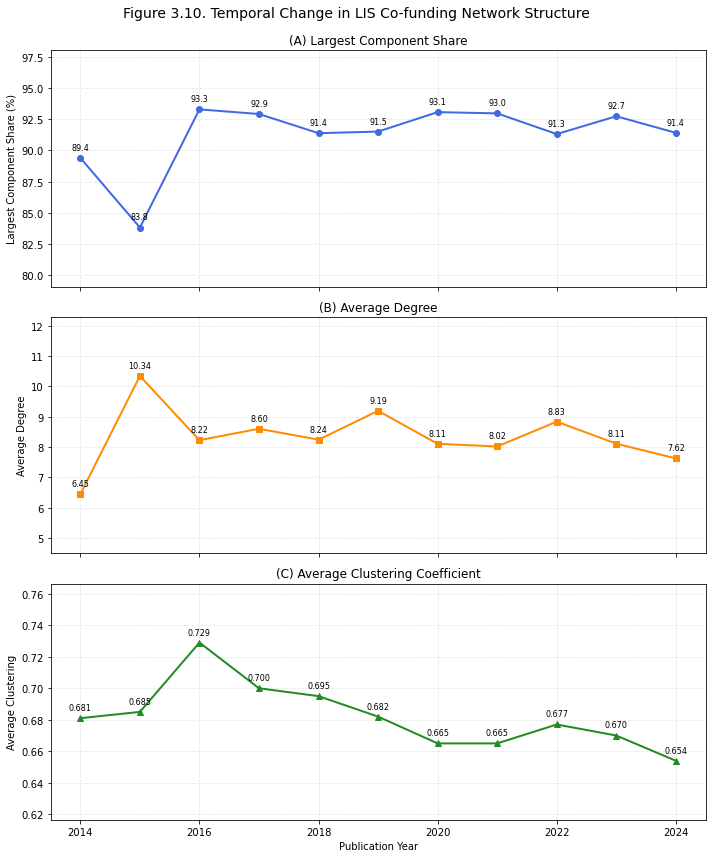

In [19]:
# ============================================================
# Figure 3.10
# Temporal Change in LIS Co-funding Network Structure
#
# Panel A: Largest Component Share (%)
# Panel B: Average Degree
# Panel C: Average Clustering Coefficient
#
# Improvements:
# 1. Expanded y-axis range to avoid exaggerated fluctuations
# 2. Value labels added to each point
# 3. Different colors for each metric
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

plot_df = table_3_6_network_stats.copy()

# ------------------------------------------------------------
# Create 3-panel figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(10, 12),
    sharex=True
)

# ============================================================
# Panel A
# Largest Component Share
# ============================================================

y = plot_df["Largest Component Share (%)"]

axes[0].plot(
    plot_df["Year"],
    y,
    marker="o",
    linewidth=2,
    color="royalblue"
)

# Add value labels
for x_val, y_val in zip(plot_df["Year"], y):
    axes[0].annotate(
        f"{y_val:.1f}",
        (x_val, y_val),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8
    )

# Add padding to y-axis
padding = (y.max() - y.min()) * 0.50

axes[0].set_ylim(
    y.min() - padding,
    y.max() + padding
)

axes[0].set_ylabel(
    "Largest Component Share (%)"
)

axes[0].set_title(
    "(A) Largest Component Share"
)

axes[0].grid(
    alpha=0.3,
    linestyle="--"
)

# ============================================================
# Panel B
# Average Degree
# ============================================================

y = plot_df["Avg Degree"]

axes[1].plot(
    plot_df["Year"],
    y,
    marker="s",
    linewidth=2,
    color="darkorange"
)

for x_val, y_val in zip(plot_df["Year"], y):
    axes[1].annotate(
        f"{y_val:.2f}",
        (x_val, y_val),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8
    )

padding = (y.max() - y.min()) * 0.50

axes[1].set_ylim(
    y.min() - padding,
    y.max() + padding
)

axes[1].set_ylabel(
    "Average Degree"
)

axes[1].set_title(
    "(B) Average Degree"
)

axes[1].grid(
    alpha=0.3,
    linestyle="--"
)

# ============================================================
# Panel C
# Average Clustering Coefficient
# ============================================================

y = plot_df["Avg Clustering"]

axes[2].plot(
    plot_df["Year"],
    y,
    marker="^",
    linewidth=2,
    color="forestgreen"
)

for x_val, y_val in zip(plot_df["Year"], y):
    axes[2].annotate(
        f"{y_val:.3f}",
        (x_val, y_val),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8
    )

padding = (y.max() - y.min()) * 0.50

axes[2].set_ylim(
    y.min() - padding,
    y.max() + padding
)

axes[2].set_ylabel(
    "Average Clustering"
)

axes[2].set_xlabel(
    "Publication Year"
)

axes[2].set_title(
    "(C) Average Clustering Coefficient"
)

axes[2].grid(
    alpha=0.3,
    linestyle="--"
)

# ============================================================
# Overall Figure Title
# ============================================================

fig.suptitle(
    "Figure 3.10. Temporal Change in LIS Co-funding Network Structure",
    fontsize=14,
    y=0.99
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

# ============================================================
# Save Figure
# ============================================================

plt.savefig(
    "Figure_3_10_Temporal_Change_LIS_Cofunding_Network.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_10_Temporal_Change_LIS_Cofunding_Network.pdf",
    bbox_inches="tight"
)

plt.show()

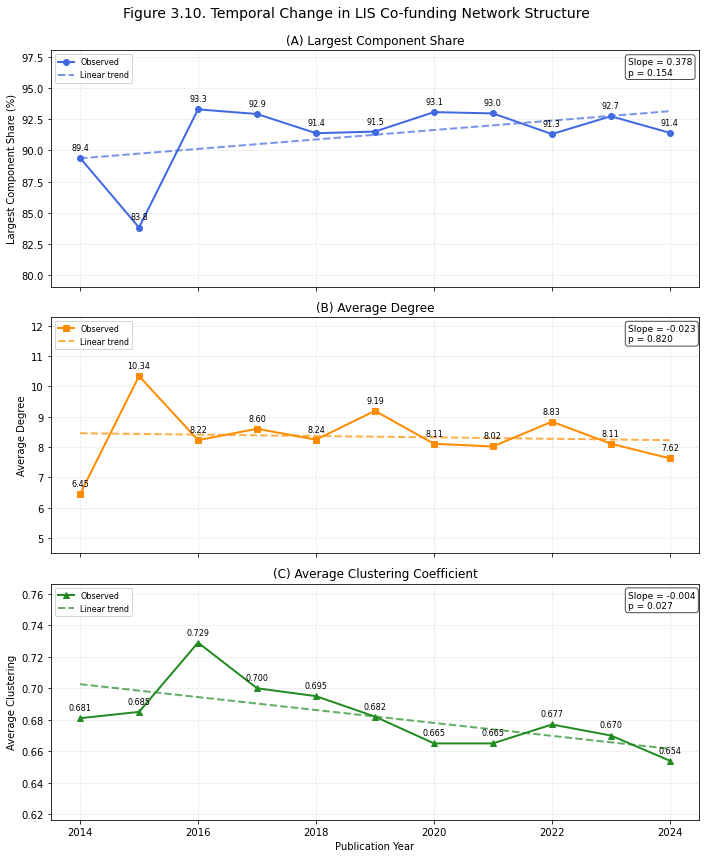

,Metric,Slope,p-value
0,Largest Component Share (%),0.3784,0.1543
1,Average Degree,-0.0228,0.8195
2,Average Clustering,-0.0041,0.0271


In [24]:
# ============================================================
# Figure 3.10
# Temporal Change in LIS Co-funding Network Structure
#
# Panel A: Largest Component Share (%)
# Panel B: Average Degree
# Panel C: Average Clustering Coefficient
#
# Features:
# 1. Expanded y-axis range
# 2. Value labels added to each point
# 3. Different colors for each metric
# 4. Linear trend line added to each panel
# 5. Slope and p-value displayed in each panel
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

plot_df = table_3_6_network_stats.copy()

# ------------------------------------------------------------
# Helper function for each panel
# ------------------------------------------------------------

def plot_metric_with_trend(
    ax,
    x,
    y,
    color,
    marker,
    title,
    ylabel,
    value_format
):

    # Observed line
    ax.plot(
        x,
        y,
        marker=marker,
        linewidth=2,
        color=color,
        label="Observed"
    )

    # Linear trend
    slope, intercept, r_value, p_value, std_err = linregress(
        x,
        y
    )

    trend = intercept + slope * x

    ax.plot(
        x,
        trend,
        linestyle="--",
        linewidth=2,
        color=color,
        alpha=0.7,
        label="Linear trend"
    )

    # Value labels
    for x_val, y_val in zip(x, y):
        ax.annotate(
            value_format.format(y_val),
            (x_val, y_val),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=8
        )

    # Add padding to y-axis
    y_range = y.max() - y.min()

    if y_range == 0:
        padding = y.max() * 0.20
    else:
        padding = y_range * 0.50

    ax.set_ylim(
        y.min() - padding,
        y.max() + padding
    )

    # Add slope and p-value
    ax.text(
        0.89,
        0.97,
        f"Slope = {slope:.3f}\n"
        f"p = {p_value:.3f}",
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment="top",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white",
            alpha=0.7
        )
    )

    ax.set_ylabel(ylabel)

    ax.set_title(title)

    ax.grid(
        alpha=0.3,
        linestyle="--"
    )

    ax.legend(
        loc="upper left",
        frameon=True,
        fontsize=8
    )

    return slope, p_value


# ------------------------------------------------------------
# Create 3-panel figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(10, 12),
    sharex=True
)

x = plot_df["Year"].values

# Panel A
slope_lcc, p_lcc = plot_metric_with_trend(
    ax=axes[0],
    x=x,
    y=plot_df["Largest Component Share (%)"].values,
    color="royalblue",
    marker="o",
    title="(A) Largest Component Share",
    ylabel="Largest Component Share (%)",
    value_format="{:.1f}"
)

# Panel B
slope_degree, p_degree = plot_metric_with_trend(
    ax=axes[1],
    x=x,
    y=plot_df["Avg Degree"].values,
    color="darkorange",
    marker="s",
    title="(B) Average Degree",
    ylabel="Average Degree",
    value_format="{:.2f}"
)

# Panel C
slope_clustering, p_clustering = plot_metric_with_trend(
    ax=axes[2],
    x=x,
    y=plot_df["Avg Clustering"].values,
    color="forestgreen",
    marker="^",
    title="(C) Average Clustering Coefficient",
    ylabel="Average Clustering",
    value_format="{:.3f}"
)

axes[2].set_xlabel("Publication Year")

# ------------------------------------------------------------
# Overall title
# ------------------------------------------------------------

fig.suptitle(
    "Figure 3.10. Temporal Change in LIS Co-funding Network Structure",
    fontsize=14,
    y=0.99
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_10_Temporal_Change_LIS_Cofunding_Network_with_Trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_10_Temporal_Change_LIS_Cofunding_Network_with_Trends.pdf",
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Optional: Create trend summary table
# ------------------------------------------------------------

figure_3_10_trend_summary = pd.DataFrame({
    "Metric": [
        "Largest Component Share (%)",
        "Average Degree",
        "Average Clustering"
    ],
    "Slope": [
        slope_lcc,
        slope_degree,
        slope_clustering
    ],
    "p-value": [
        p_lcc,
        p_degree,
        p_clustering
    ]
})

figure_3_10_trend_summary = figure_3_10_trend_summary.round(4)

figure_3_10_trend_summary

8. Journal Quartile Comparison

In [25]:
# ============================================================
# Table 3.7
# Network Comparison by Journal Quartile
#
# Node:
#   Funding organization
#
# Edge:
#   Co-funding relationship between two funders
#
# Edge weight:
#   Number of co-funded papers within each journal quartile
# ============================================================

import pandas as pd
import networkx as nx

# ------------------------------------------------------------
# Load journal ranking data
# ------------------------------------------------------------

journal_df = pd.read_csv("journal_list.csv")

# ------------------------------------------------------------
# Clean journal names for reliable merge
# ------------------------------------------------------------

df["Source_title_clean"] = (
    df["Source title"]
    .astype(str)
    .str.strip()
    .str.lower()
)

journal_df["Journal_name_clean"] = (
    journal_df["Journal_name"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# ------------------------------------------------------------
# Create journal quartiles
# Q1 = highest-ranked journals
# Q4 = lowest-ranked journals
# ------------------------------------------------------------

journal_df["Quartile"] = pd.qcut(
    journal_df["Ranking"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

# ------------------------------------------------------------
# Merge quartile information into paper-level data
# ------------------------------------------------------------

df_quartile = df.merge(
    journal_df[
        [
            "Journal_name_clean",
            "Ranking",
            "Quartile"
        ]
    ],
    left_on="Source_title_clean",
    right_on="Journal_name_clean",
    how="left"
)

print("Unmatched papers:")
print(df_quartile["Quartile"].isna().sum())

Unmatched papers:
0


In [26]:
# ============================================================
# Add journal quartile to paper-level edge list
# ============================================================

paper_quartile = df_quartile[
    [
        "Paper_id",
        "Quartile"
    ]
].drop_duplicates()

paper_edge_quartile = paper_edge_list.merge(
    paper_quartile,
    on="Paper_id",
    how="left"
)

print("Unmatched paper-level edges:")
print(paper_edge_quartile["Quartile"].isna().sum())

Unmatched paper-level edges:
0


In [27]:
# ============================================================
# Function:
# Build quartile-specific co-funding network
# ============================================================

def build_quartile_network(edge_df, quartile):

    q_edges = edge_df[
        edge_df["Quartile"] == quartile
    ].copy()

    q_weighted_edges = (
        q_edges
        .groupby(["Funder_A", "Funder_B"])
        .size()
        .reset_index(name="Weight")
    )

    G_q = nx.Graph()

    for _, row in q_weighted_edges.iterrows():
        G_q.add_edge(
            row["Funder_A"],
            row["Funder_B"],
            weight=row["Weight"]
        )

    return G_q


# ============================================================
# Function:
# Calculate network statistics
# ============================================================

def calculate_quartile_network_statistics(G, quartile):

    nodes = G.number_of_nodes()
    edges = G.number_of_edges()

    if nodes == 0:
        return {
            "Quartile": quartile,
            "Nodes": 0,
            "Edges": 0,
            "Density": 0,
            "Components": 0,
            "Largest Component Size": 0,
            "Largest Component Share (%)": 0,
            "Avg Degree": 0,
            "Avg Weighted Degree": 0,
            "Avg Clustering": 0,
            "Avg Weighted Clustering": 0
        }

    components = list(nx.connected_components(G))

    num_components = len(components)

    largest_component_size = len(
        max(components, key=len)
    )

    largest_component_share = (
        largest_component_size / nodes * 100
    )

    avg_degree = (
        sum(dict(G.degree()).values()) / nodes
    )

    avg_weighted_degree = (
        sum(dict(G.degree(weight="weight")).values()) / nodes
    )

    density = nx.density(G)

    avg_clustering = nx.average_clustering(G)

    avg_weighted_clustering = nx.average_clustering(
        G,
        weight="weight"
    )

    return {
        "Quartile": quartile,
        "Nodes": nodes,
        "Edges": edges,
        "Density": density,
        "Components": num_components,
        "Largest Component Size": largest_component_size,
        "Largest Component Share (%)": largest_component_share,
        "Avg Degree": avg_degree,
        "Avg Weighted Degree": avg_weighted_degree,
        "Avg Clustering": avg_clustering,
        "Avg Weighted Clustering": avg_weighted_clustering
    }

In [28]:
# ============================================================
# Create Table 3.7
# Network Comparison by Journal Quartile
# ============================================================

quartiles = ["Q1", "Q2", "Q3", "Q4"]

quartile_network_stats = []

quartile_graphs = {}

for q in quartiles:

    G_q = build_quartile_network(
        paper_edge_quartile,
        q
    )

    quartile_graphs[q] = G_q

    stats = calculate_quartile_network_statistics(
        G_q,
        q
    )

    quartile_network_stats.append(stats)

table_3_7_quartile_network_stats = pd.DataFrame(
    quartile_network_stats
)

table_3_7_quartile_network_stats = (
    table_3_7_quartile_network_stats
    .round({
        "Density": 6,
        "Largest Component Share (%)": 2,
        "Avg Degree": 3,
        "Avg Weighted Degree": 3,
        "Avg Clustering": 3,
        "Avg Weighted Clustering": 4
    })
)

table_3_7_quartile_network_stats

,Quartile,Nodes,Edges,Density,Components,Largest Component Size,Largest Component Share (%),Avg Degree,Avg Weighted Degree,Avg Clustering,Avg Weighted Clustering
0,Q1,7386,53098,0.001947,87,7197,97.44,14.378,22.224,0.679,0.0024
1,Q2,2323,7277,0.002698,117,2036,87.65,6.265,7.393,0.606,0.0180
2,Q3,2767,10715,0.002800,110,2504,90.50,7.745,9.594,0.648,0.0079
3,Q4,1478,4424,0.004053,81,1294,87.55,5.986,6.958,0.651,0.0248


In [29]:
table_3_7_quartile_network_stats.to_csv(
    "Table_3_7_Network_Comparison_by_Journal_Quartile_LIS.csv",
    index=False
)

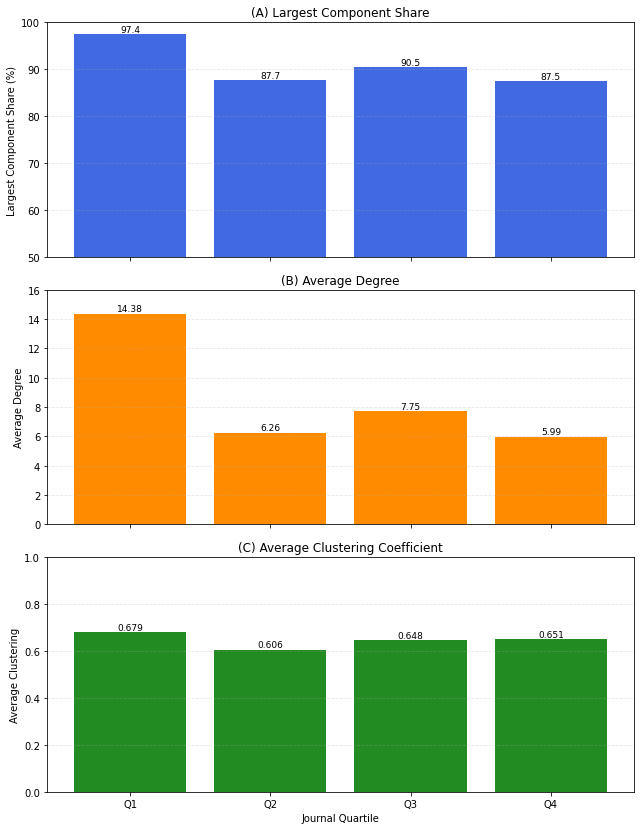

In [32]:
# ============================================================
# Figure 3.11
# Network Comparison by Journal Quartile
#
# Panel A: Largest Component Share (%)
# Panel B: Average Degree
# Panel C: Average Clustering Coefficient
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

plot_df = table_3_7_quartile_network_stats.copy()

# Ensure quartile order
plot_df["Quartile"] = pd.Categorical(
    plot_df["Quartile"],
    categories=["Q1", "Q2", "Q3", "Q4"],
    ordered=True
)

plot_df = plot_df.sort_values("Quartile")

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(9, 12),
    sharex=True
)

# ------------------------------------------------------------
# Helper function
# ------------------------------------------------------------

def plot_quartile_bar(
    ax,
    x,
    y,
    title,
    ylabel,
    value_format,
    color
):

    bars = ax.bar(
        x,
        y,
        color=color
    )

    for bar, value in zip(bars, y):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            value_format.format(value),
            ha="center",
            va="bottom",
            fontsize=9
        )

    padding = (max(y) - min(y)) * 0.20

    ax.set_ylim(
        min(y) - padding,
        max(y) + padding
    )

    ax.set_title(title)

    ax.set_ylabel(ylabel)

    ax.grid(
        axis="y",
        alpha=0.3,
        linestyle="--"
    )


# Panel A
plot_quartile_bar(
    ax=axes[0],
    x=plot_df["Quartile"],
    y=plot_df["Largest Component Share (%)"],
    title="(A) Largest Component Share",
    ylabel="Largest Component Share (%)",
    value_format="{:.1f}",
    color="royalblue"
)

# Panel B
plot_quartile_bar(
    ax=axes[1],
    x=plot_df["Quartile"],
    y=plot_df["Avg Degree"],
    title="(B) Average Degree",
    ylabel="Average Degree",
    value_format="{:.2f}",
    color="darkorange"
)

# Panel C
plot_quartile_bar(
    ax=axes[2],
    x=plot_df["Quartile"],
    y=plot_df["Avg Clustering"],
    title="(C) Average Clustering Coefficient",
    ylabel="Average Clustering",
    value_format="{:.3f}",
    color="forestgreen"
)

axes[2].set_xlabel("Journal Quartile")

# fig.suptitle(
#     "Figure 3.11. Network Comparison by Journal Quartile",
#     fontsize=14,
#     y=0.99
# )

# ------------------------------------------------------------
# Set consistent y-axis ranges
# ------------------------------------------------------------

# Panel A
axes[0].set_ylim(50, 100)

# Panel B
axes[1].set_ylim(0, 16)

# Panel C
axes[2].set_ylim(0, 1)


plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_3_11_Network_Comparison_by_Journal_Quartile_LIS.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_3_11_Network_Comparison_by_Journal_Quartile_LIS.pdf",
    bbox_inches="tight"
)

plt.show()

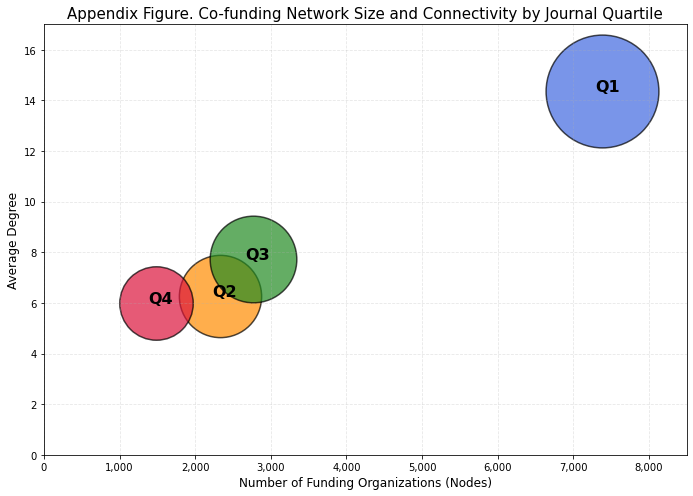

In [44]:
# ============================================================
# Appendix Figure
# Bubble Chart:
# Network Size and Connectivity by Journal Quartile
#
# x-axis  : Number of Nodes
# y-axis  : Average Degree
# bubble  : Largest Component Size
# color   : Journal Quartile
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

bubble_df = table_3_7_quartile_network_stats.copy()

# ------------------------------------------------------------
# Ensure quartile order
# ------------------------------------------------------------

bubble_df["Quartile"] = pd.Categorical(
    bubble_df["Quartile"],
    categories=["Q1", "Q2", "Q3", "Q4"],
    ordered=True
)

bubble_df = bubble_df.sort_values("Quartile")

# ------------------------------------------------------------
# Bubble colors
# ------------------------------------------------------------

quartile_colors = {
    "Q1": "royalblue",
    "Q2": "darkorange",
    "Q3": "forestgreen",
    "Q4": "crimson"
}

# ------------------------------------------------------------
# Bubble size
#
# Scale Largest Component Size for visualization.
# You can adjust the divisor (currently 0.8) if desired.
# ------------------------------------------------------------

# bubble_sizes = (
#     bubble_df["Largest Component Size"] * 1.2
# )

import numpy as np

bubble_sizes = np.sqrt(
    bubble_df["Largest Component Size"]
) * 150

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

# Draw bubbles one by one
for i, row in bubble_df.iterrows():

    plt.scatter(
        row["Nodes"],
        row["Avg Degree"],
        s=bubble_sizes.loc[i],
        color=quartile_colors[row["Quartile"]],
        alpha=0.70,
        edgecolors="black",
        linewidth=1.5
    )

    # Label
    plt.text(
#         row["Nodes"] + 120,
        row["Nodes"] - 100,
#         row["Avg Degree"] + 0.25,
        row["Avg Degree"],
        row["Quartile"],
        fontsize=16,
        fontweight="bold"
    )

# ------------------------------------------------------------
# Axis ranges
# ------------------------------------------------------------

plt.xlim(0, 8500)

plt.ylim(0, 17)

# Format x-axis with thousands separators

from matplotlib.ticker import StrMethodFormatter
plt.gca().xaxis.set_major_formatter(
    StrMethodFormatter('{x:,.0f}')
)

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

plt.xlabel(
    "Number of Funding Organizations (Nodes)",
    fontsize=12
)

plt.ylabel(
    "Average Degree",
    fontsize=12
)

plt.title(
    "Appendix Figure. Co-funding Network Size and Connectivity by Journal Quartile",
    fontsize=15
)

plt.grid(
    alpha=0.3,
    linestyle="--"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Appendix_Bubble_Chart_Quartile_Network_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Appendix_Bubble_Chart_Quartile_Network_Comparison.pdf",
    bbox_inches="tight"
)

plt.show()

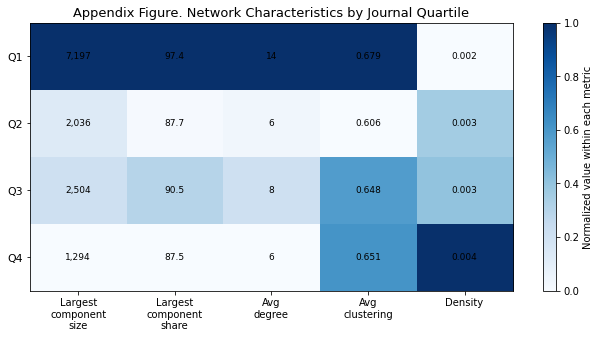

In [45]:
# ============================================================
# Appendix Figure
# Heatmap of Normalized Network Characteristics by Quartile
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

heatmap_df = table_3_7_quartile_network_stats.copy()

heatmap_df["Quartile"] = pd.Categorical(
    heatmap_df["Quartile"],
    categories=["Q1", "Q2", "Q3", "Q4"],
    ordered=True
)

heatmap_df = heatmap_df.sort_values("Quartile")

metrics = [
    "Largest Component Size",
    "Largest Component Share (%)",
    "Avg Degree",
    "Avg Clustering",
    "Density"
]

heatmap_data = heatmap_df.set_index("Quartile")[metrics]

# Min-max normalize each metric
heatmap_norm = (
    heatmap_data - heatmap_data.min()
) / (
    heatmap_data.max() - heatmap_data.min()
)

fig, ax = plt.subplots(figsize=(9, 4.8))

im = ax.imshow(
    heatmap_norm,
    aspect="auto",
    cmap="Blues",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(metrics)))
ax.set_xticklabels(
    [
        "Largest\ncomponent\nsize",
        "Largest\ncomponent\nshare",
        "Avg\ndegree",
        "Avg\nclustering",
        "Density"
    ],
    fontsize=10
)

ax.set_yticks(range(len(heatmap_norm.index)))
ax.set_yticklabels(heatmap_norm.index, fontsize=11)

# Add original values inside cells
for i in range(heatmap_norm.shape[0]):
    for j in range(heatmap_norm.shape[1]):
        original_value = heatmap_data.iloc[i, j]

        if metrics[j] in ["Density", "Avg Clustering"]:
            label = f"{original_value:.3f}"
        elif metrics[j] == "Largest Component Share (%)":
            label = f"{original_value:.1f}"
        else:
            label = f"{original_value:,.0f}"

        ax.text(
            j,
            i,
            label,
            ha="center",
            va="center",
            fontsize=9
        )

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Normalized value within each metric", fontsize=10)

ax.set_title(
    "Appendix Figure. Network Characteristics by Journal Quartile",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    "Appendix_Heatmap_Network_Characteristics_by_Quartile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Appendix_Heatmap_Network_Characteristics_by_Quartile.pdf",
    bbox_inches="tight"
)

plt.show()

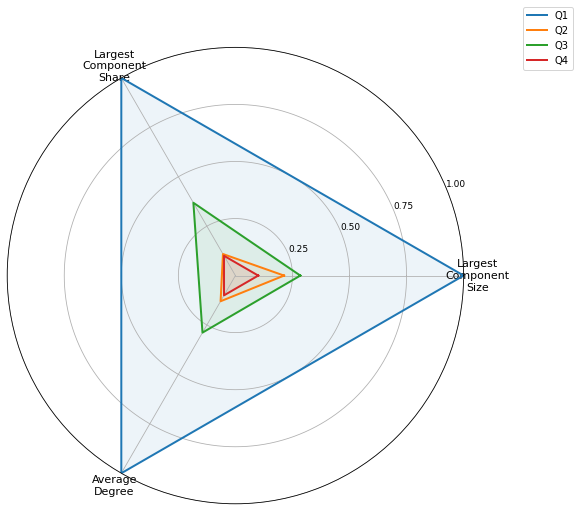

In [49]:
# ============================================================
# Appendix Figure
# Radar Chart:
# Co-funding Network Characteristics by Journal Quartile
#
# Metrics:
# - Largest Component Size
# - Largest Component Share (%)
# - Average Degree
#
# Note:
# Values are min-max normalized within each metric.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

radar_df = table_3_7_quartile_network_stats.copy()

# ------------------------------------------------------------
# Ensure quartile order
# ------------------------------------------------------------

radar_df["Quartile"] = pd.Categorical(
    radar_df["Quartile"],
    categories=["Q1", "Q2", "Q3", "Q4"],
    ordered=True
)

radar_df = radar_df.sort_values("Quartile")

# ------------------------------------------------------------
# Select metrics
# ------------------------------------------------------------

metrics = [
    "Largest Component Size",
    "Largest Component Share (%)",
    "Avg Degree"
]

metric_labels = [
    "Largest\nComponent\nSize",
    "Largest\nComponent\nShare",
    "Average\nDegree"
]

# ------------------------------------------------------------
# Min-max normalization with lower bound
# This prevents the lowest quartile from disappearing at zero.
# ------------------------------------------------------------

lower_bound = 0.10

radar_norm = radar_df.copy()

for metric in metrics:
    min_val = radar_df[metric].min()
    max_val = radar_df[metric].max()

    radar_norm[metric] = (
        lower_bound
        + (1 - lower_bound)
        * (radar_df[metric] - min_val)
        / (max_val - min_val)
    )

# ------------------------------------------------------------
# Radar chart setup
# ------------------------------------------------------------

num_vars = len(metrics)

angles = np.linspace(
    0,
    2 * np.pi,
    num_vars,
    endpoint=False
).tolist()

# Close the polygon
angles += angles[:1]

fig, ax = plt.subplots(
    figsize=(8, 8),
    subplot_kw=dict(polar=True)
)

# ------------------------------------------------------------
# Plot each quartile
# ------------------------------------------------------------

for _, row in radar_norm.iterrows():

    values = row[metrics].tolist()
    values += values[:1]

    ax.plot(
        angles,
        values,
        linewidth=2,
        label=row["Quartile"]
    )

    ax.fill(
        angles,
        values,
        alpha=0.08
    )

# ------------------------------------------------------------
# Axis formatting
# ------------------------------------------------------------

ax.set_xticks(angles[:-1])
ax.set_xticklabels(
    metric_labels,
    fontsize=11
)

ax.set_ylim(0, 1)

ax.set_yticks(
    [0.25, 0.50, 0.75, 1.00]
)

ax.set_yticklabels(
    ["0.25", "0.50", "0.75", "1.00"],
    fontsize=9
)

# ax.set_title(
#     "Appendix Figure. Radar Chart of Co-funding Network Characteristics by Journal Quartile\n"
#     "Values are rescaled to 0.10–1.00 within each metric",
#     y=1.10,
#     fontsize=13
# )

ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.25, 1.10),
    frameon=True
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Appendix_Radar_Chart_Three_Metrics_by_Quartile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Appendix_Radar_Chart_Three_Metrics_by_Quartile.pdf",
    bbox_inches="tight"
)

plt.show()